# 11. Experiment 1 — Dataset inspection

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\tasdus_117\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


--- 1. TẢI DỮ LIỆU IMDB ---
--- 2. THỐNG KÊ CƠ BẢN ---
• Số samples: 50000 (Train: 25000, Test: 25000)
• Số classes: 2
• Class distribution: {0: 25000, 1: 25000} (0: Negative, 1: Positive)
• Missing text: 0
• Missing labels: 0
• Duplicate documents: 418

--- 3. TÍNH TOÁN SEQUENCE LENGTH ---
• Minimum sequence length: 4 tokens
• Maximum sequence length: 2470 tokens
• Mean sequence length: 231.16 tokens
• Median sequence length: 173.0 tokens
• 90th Percentile: 451.0 tokens

--- 4. VẼ HISTOGRAM SEQUENCE LENGTH ---


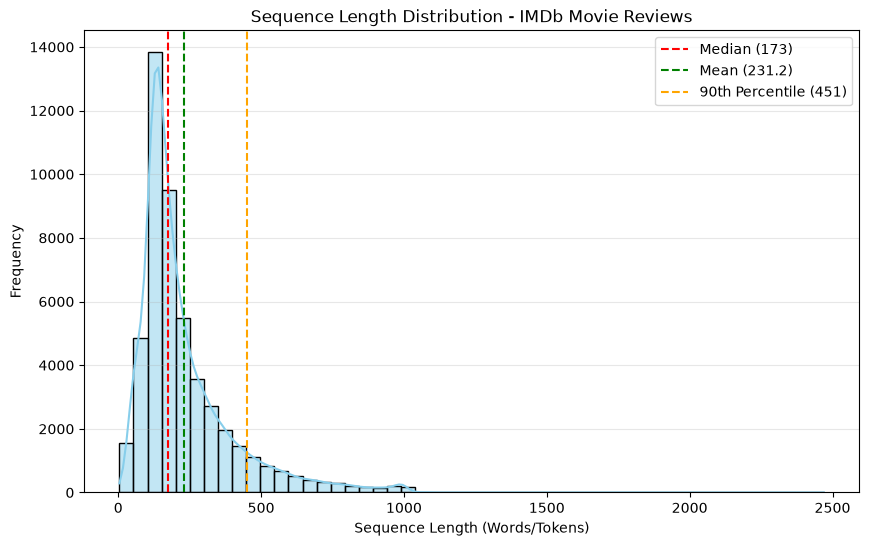

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
import nltk

nltk.download('punkt')

print("--- 1. TẢI DỮ LIỆU IMDB ---")
# Thêm namespace stanfordnlp/ trước tên imdb
dataset = load_dataset("stanfordnlp/imdb")
train_df = pd.DataFrame(dataset['train'])
test_df = pd.DataFrame(dataset['test'])
df = pd.concat([train_df, test_df], ignore_index=True)

print("--- 2. THỐNG KÊ CƠ BẢN ---")
num_samples = len(df)
num_classes = df['label'].nunique()
class_dist = df['label'].value_counts().to_dict()

missing_text = df['text'].isnull().sum()
missing_labels = df['label'].isnull().sum()
duplicate_docs = df['text'].duplicated().sum()

print(f"• Số samples: {num_samples} (Train: {len(train_df)}, Test: {len(test_df)})")
print(f"• Số classes: {num_classes}")
print(f"• Class distribution: {class_dist} (0: Negative, 1: Positive)")
print(f"• Missing text: {missing_text}")
print(f"• Missing labels: {missing_labels}")
print(f"• Duplicate documents: {duplicate_docs}")

print("\n--- 3. TÍNH TOÁN SEQUENCE LENGTH ---")
df['doc_len'] = df['text'].apply(lambda x: len(x.split()))

min_len = df['doc_len'].min()
max_len = df['doc_len'].max()
mean_len = df['doc_len'].mean()
median_len = df['doc_len'].median()
p90_len = np.percentile(df['doc_len'], 90)

print(f"• Minimum sequence length: {min_len} tokens")
print(f"• Maximum sequence length: {max_len} tokens")
print(f"• Mean sequence length: {mean_len:.2f} tokens")
print(f"• Median sequence length: {median_len:.1f} tokens")
print(f"• 90th Percentile: {p90_len:.1f} tokens")

print("\n--- 4. VẼ HISTOGRAM SEQUENCE LENGTH ---")
plt.figure(figsize=(10, 6))
sns.histplot(df['doc_len'], bins=50, kde=True, color='skyblue', edgecolor='black')
plt.axvline(median_len, color='red', linestyle='--', label=f'Median ({median_len:.0f})')
plt.axvline(mean_len, color='green', linestyle='--', label=f'Mean ({mean_len:.1f})')
plt.axvline(p90_len, color='orange', linestyle='--', label=f'90th Percentile ({p90_len:.0f})')

plt.title('Sequence Length Distribution - IMDb Movie Reviews')
plt.xlabel('Sequence Length (Words/Tokens)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

1. Phân vị tích lũy:
  - Trong ảnh, giá trị 90th Percentile là 451.0 tokens. Điều này có nghĩa là nếu chọn max_length = 451 (hoặc tròn thành $256$ / $512$), sẽ giữ lại được trọn vẹn nội dung của 90% số lượng bài review mà không bị truncate.   
  - Nên chọn max_length sao cho bao phủ từ 85% đến 95% tập dữ liệu để tối ưu lượng thông tin giữ lại.
2. Hình dạng phân bố & Hiện tượng Over-padding:
  - Biểu đồ thể hiện phân bố bị lệch phải rất mạnh:   
    - Median = 173 tokens   
    - Mean = 231.16 tokens   
    - Maximum = 2470 tokens   
  - Do có các bài review ngoại lệ kéo dài tới $2470$ tokens, nếu chọn max_length theo $Max$, hơn $90\%$ các văn bản còn lại sẽ bị độn thêm quá nhiều token $PAD$ ($0$). Việc này gây lãng phí tài nguyên tính toán và khiến mô hình phải xử lý lượng lớn dữ liệu rác.   
3. Giới hạn cơ chế mô hình:
  - Các mô hình chuỗi như RNN và LSTM gặp hiện tượng suy giảm tín hiệu khi truyền qua thời gian quá dài.
  - Thông tin cảm xúc cốt lõi trong các bài review IMDb thường tập trung ở phần đầu hoặc câu kết luận ở cuối. Việc mở rộng max_length lên quá cao ($> 500$) không mang lại thêm nhiều giá trị ngữ nghĩa cho bài toán phân loại cảm xúc.
4. Kết luận:
- Nên chọn max_length = 256 hoặc max_length = 512.
  - Với max_length = 256: Bao phủ được hơn $70\%$ số bài review, tốc độ huấn luyện nhanh và nhẹ bộ nhớ.   
  - Với max_length = 512: Bao phủ hơn $90\%$ số bài review, đảm bảo giữ lại hầu như toàn bộ ngữ cảnh quan trọng mà không lãng phí tài nguyên cho các bài quá dài.   

# 13. Experiment 2 — Padding và truncation

Đang sử dụng thiết bị: cuda
Đang tải tập dữ liệu IMDb...


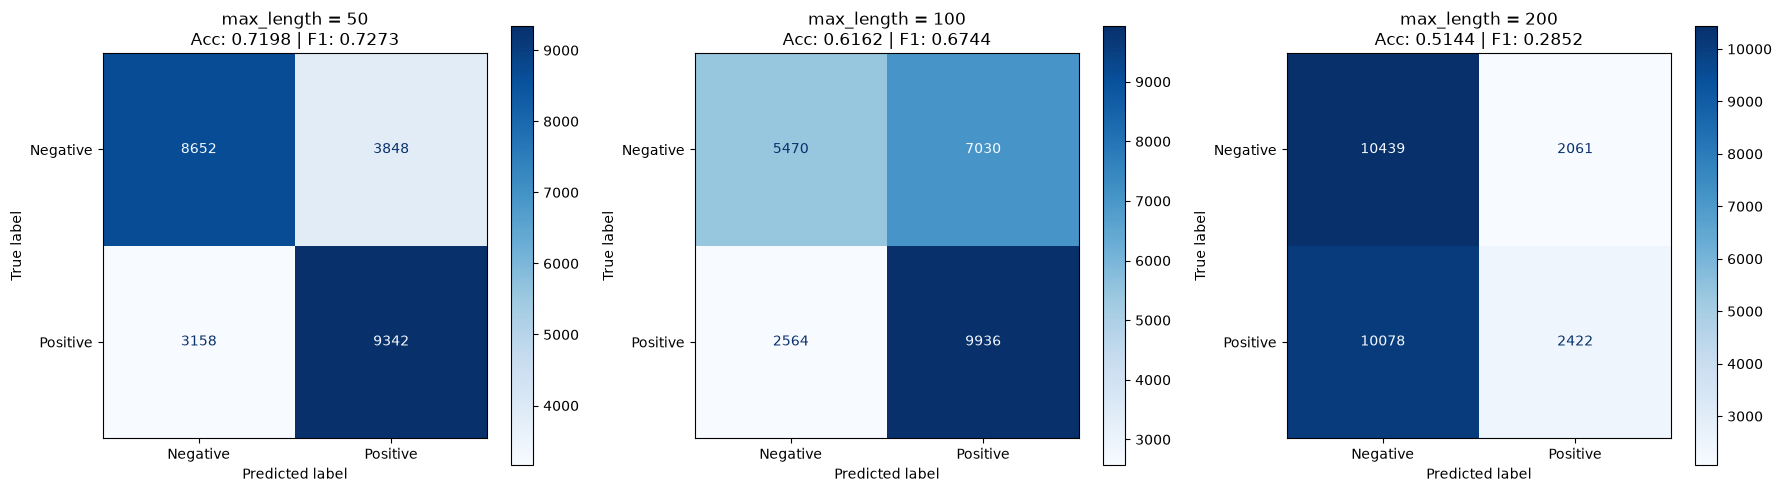


─────────────────────────────────────────────────────────────────
Max length   % tokens retained    Training time   Accuracy   F1   
─────────────────────────────────────────────────────────────────
        50             21.54%         0.74s     0.7198 0.7273
       100             41.60%         0.72s     0.6162 0.6744
       200             68.66%         0.76s     0.5144 0.2852
─────────────────────────────────────────────────────────────────


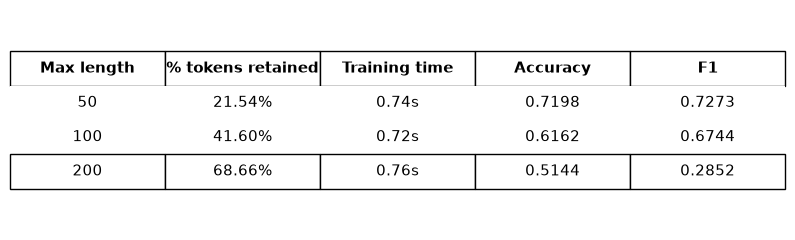


[THÔNG BÁO] Đã lưu thành công 2 file ảnh:
 1. confusion_matrix.png
 2. results_table.png


In [4]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# 1. Thiết lập thiết bị tính toán
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {DEVICE}")

# Hyperparameters
VOCAB_SIZE = 10000
EMBED_DIM = 64
HIDDEN_DIM = 64
BATCH_SIZE = 64
EPOCHS = 3

# 2. Tải và tiền xử lý dữ liệu IMDb từ Hugging Face
print("Đang tải tập dữ liệu IMDb...")
dataset = load_dataset("stanfordnlp/imdb")

# Xây dựng Vocab đơn giản từ tập Train
from collections import Counter
word_counts = Counter()
for text in dataset['train']['text']:
    word_counts.update(text.lower().split())

vocab = {word: i + 2 for i, (word, _) in enumerate(word_counts.most_common(VOCAB_SIZE - 2))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def encode_text(text):
    return [vocab.get(word, 1) for word in text.lower().split()]

x_train_raw = [encode_text(t) for t in dataset['train']['text']]
y_train = np.array(dataset['train']['label'])
x_test_raw = [encode_text(t) for t in dataset['test']['text']]
y_test = np.array(dataset['test']['label'])

total_orig_tokens = sum([len(seq) for seq in x_train_raw]) + sum([len(seq) for seq in x_test_raw])

def pad_sequences(sequences, maxlen):
    padded = np.zeros((len(sequences), maxlen), dtype=np.int64)
    for i, seq in enumerate(sequences):
        if len(seq) > 0:
            trunc = seq[:maxlen]
            padded[i, :len(trunc)] = trunc
    return padded

# 3. Định nghĩa mô hình LSTM
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super(SentimentLSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        x = self.embedding(x)
        _, (h_n, _) = self.lstm(x)
        out = self.fc(h_n[-1])
        return out.squeeze(1)

# 4. Thực nghiệm với max_length = 50, 100, 200
max_lengths = [50, 100, 200]
results = []

fig_cm, axes_cm = plt.subplots(1, 3, figsize=(18, 5))

for idx, ml in enumerate(max_lengths):
    # Tính % tokens retained
    retained_train = sum([min(len(seq), ml) for seq in x_train_raw])
    retained_test = sum([min(len(seq), ml) for seq in x_test_raw])
    pct_retained = ((retained_train + retained_test) / total_orig_tokens) * 100
    
    # Padding / Truncation
    x_tr_pad = pad_sequences(x_train_raw, maxlen=ml)
    x_te_pad = pad_sequences(x_test_raw, maxlen=ml)
    
    train_dataset = TensorDataset(torch.tensor(x_tr_pad, dtype=torch.long), torch.tensor(y_train, dtype=torch.float32))
    test_dataset = TensorDataset(torch.tensor(x_te_pad, dtype=torch.long), torch.tensor(y_test, dtype=torch.float32))
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    # Setup Model
    model = SentimentLSTM(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    
    # Training Loop
    start_time = time.time()
    for epoch in range(EPOCHS):
        model.train()
        for seqs, labels in train_loader:
            seqs, labels = seqs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(seqs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
    avg_train_time = (time.time() - start_time) / EPOCHS
    
    # Evaluation
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for seqs, labels in test_loader:
            seqs = seqs.to(DEVICE)
            outputs = torch.sigmoid(model(seqs))
            preds = (outputs > 0.5).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
            
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    
    # Vẽ Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
    disp.plot(ax=axes_cm[idx], cmap=plt.cm.Blues, values_format='d')
    axes_cm[idx].set_title(f'max_length = {ml}\nAcc: {acc:.4f} | F1: {f1:.4f}')

    results.append({
        'max_length': ml,
        'pct_retained': f"{pct_retained:.2f}%",
        'train_time': f"{avg_train_time:.2f}s",
        'accuracy': f"{acc:.4f}",
        'f1': f"{f1:.4f}"
    })

# Lưu ảnh Confusion Matrix
fig_cm.tight_layout()
fig_cm.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# 5. In kết quả ra màn hình
print("\n" + "─"*65)
print(f"{'Max length':<12} {'% tokens retained':<20} {'Training time':<15} {'Accuracy':<10} {'F1':<5}")
print("─"*65)
for r in results:
    print(f"{r['max_length']:>10} {r['pct_retained']:>18} {r['train_time']:>13} {r['accuracy']:>10} {r['f1']:>6}")
print("─"*65)

# 6. Vẽ và xuất BẢNG KẾT QUẢ ra file ảnh (results_table.png)
fig_tbl, ax_tbl = plt.subplots(figsize=(8, 2.5))
ax_tbl.axis('off')

# Chuẩn bị dữ liệu bảng
columns = ['Max length', '% tokens retained', 'Training time', 'Accuracy', 'F1']
cell_data = [[r['max_length'], r['pct_retained'], r['train_time'], r['accuracy'], r['f1']] for r in results]

table = ax_tbl.table(cellText=cell_data, colLabels=columns, loc='center', cellLoc='center')

# Định dạng bảng
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.8)

# Tạo đường kẻ đen ngang trên/dưới dạng báo cáo academic
for (row, col), cell in table.get_celld().items():
    cell.set_linewidth(0)
    if row == 0:
        cell.set_linewidth(1)
        cell.set_linestyle('-')
        cell.get_text().set_weight('bold')
    elif row == len(results):
        cell.set_linewidth(1)
        cell.set_linestyle('-')

fig_tbl.tight_layout()
fig_tbl.savefig('results_table.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n[THÔNG BÁO] Đã lưu thành công 2 file ảnh:")
print(" 1. confusion_matrix.png")
print(" 2. results_table.png")

# 15. Experiment 3 — Baseline

In [5]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from collections import Counter

# 1. Thiết lập thiết bị tính toán
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {DEVICE}")

# Hyperparameters
VOCAB_SIZE = 10000
MAX_LEN = 100
EMBED_DIM = 64
HIDDEN_DIM = 64
BATCH_SIZE = 64
EPOCHS = 5

# 2. Tải tập dữ liệu IMDb từ Hugging Face
print("\n--- 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---")
dataset = load_dataset("stanfordnlp/imdb")

train_texts = dataset['train']['text']
train_labels = np.array(dataset['train']['label'])
test_texts = dataset['test']['text']
test_labels = np.array(dataset['test']['label'])

# =====================================================================
# MODEL 1: TF-IDF + LOGISTIC REGRESSION (BASELINE FROM LAB 04)
# =====================================================================
print("\n--- 2. HUẤN LUYỆN BASELINE: TF-IDF + LOGISTIC REGRESSION ---")
start_tf = time.time()

vectorizer = TfidfVectorizer(max_features=VOCAB_SIZE, stop_words='english')
X_train_tfidf = vectorizer.fit_transform(train_texts)
X_test_tfidf = vectorizer.transform(test_texts)

clf = LogisticRegression(max_iter=1000, C=1.0)
clf.fit(X_train_tfidf, train_labels)

time_lr = time.time() - start_tf

preds_lr = clf.predict(X_test_tfidf)
acc_lr = accuracy_score(test_labels, preds_lr)
prec_lr = precision_score(test_labels, preds_lr)
rec_lr = recall_score(test_labels, preds_lr)
f1_lr = f1_score(test_labels, preds_lr)

print(f"Logistic Regression done in {time_lr:.2f}s | Acc: {acc_lr:.4f} | F1: {f1_lr:.4f}")

# =====================================================================
# MODEL 2: EMBEDDING + SIMPLE RNN + CLASSIFIER
# =====================================================================
print("\n--- 3. HUẤN LUYỆN MODEL: EMBEDDING + SIMPLE RNN ---")

# Xây dựng Vocabulary cho RNN
word_counts = Counter()
for text in train_texts:
    word_counts.update(text.lower().split())

vocab = {word: i + 2 for i, (word, _) in enumerate(word_counts.most_common(VOCAB_SIZE - 2))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def encode_and_pad(texts, maxlen):
    encoded = []
    for text in texts:
        tokens = [vocab.get(word, 1) for word in text.lower().split()][:maxlen]
        if len(tokens) < maxlen:
            tokens = tokens + [0] * (maxlen - len(tokens))
        encoded.append(tokens)
    return np.array(encoded, dtype=np.int64)

X_train_rnn = encode_and_pad(train_texts, MAX_LEN)
X_test_rnn = encode_and_pad(test_texts, MAX_LEN)

train_dataset = TensorDataset(torch.tensor(X_train_rnn, dtype=torch.long), torch.tensor(train_labels, dtype=torch.float32))
test_dataset = TensorDataset(torch.tensor(X_test_rnn, dtype=torch.long), torch.tensor(test_labels, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

class SimpleRNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super(SimpleRNNClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True, nonlinearity='tanh')
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        x = self.embedding(x)
        out, h_n = self.rnn(x)
        logits = self.fc(h_n[-1])
        return logits.squeeze(1)

model_rnn = SimpleRNNClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_rnn.parameters(), lr=0.001)

start_rnn = time.time()
for epoch in range(EPOCHS):
    model_rnn.train()
    total_loss = 0
    for seqs, labels in train_loader:
        seqs, labels = seqs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model_rnn(seqs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"RNN Epoch {epoch+1}/{EPOCHS} - Loss: {total_loss/len(train_loader):.4f}")

time_rnn = time.time() - start_rnn

model_rnn.eval()
preds_rnn = []
with torch.no_grad():
    for seqs, _ in test_loader:
        seqs = seqs.to(DEVICE)
        outputs = torch.sigmoid(model_rnn(seqs))
        preds_rnn.extend((outputs > 0.5).cpu().numpy())

acc_rnn = accuracy_score(test_labels, preds_rnn)
prec_rnn = precision_score(test_labels, preds_rnn)
rec_rnn = recall_score(test_labels, preds_rnn)
f1_rnn = f1_score(test_labels, preds_rnn)

# =====================================================================
# 4. TỔNG HỢP KẾT QUẢ VÀ XUẤT OUTPUT
# =====================================================================
results = [
    {
        'Model': 'Logistic Regression',
        'Representation': 'TF-IDF',
        'Accuracy': round(acc_lr, 4),
        'Precision': round(prec_lr, 4),
        'Recall': round(rec_lr, 4),
        'F1': round(f1_lr, 4),
        'Training time': f"{time_lr:.2f}s"
    },
    {
        'Model': 'RNN',
        'Representation': 'Embedding',
        'Accuracy': round(acc_rnn, 4),
        'Precision': round(prec_rnn, 4),
        'Recall': round(rec_rnn, 4),
        'F1': round(f1_rnn, 4),
        'Training time': f"{time_rnn:.2f}s"
    }
]

df_res = pd.DataFrame(results)
df_res.to_csv('results_baseline.csv', index=False, encoding='utf-8')
print("\n[THÔNG BÁO] Đã lưu bảng kết quả vào: results_baseline.csv")
print("\nNội dung bảng kết quả:")
print(df_res.to_string(index=False))

# Vẽ Bảng Kết Quả (results_baseline_table.png)
fig_tbl, ax_tbl = plt.subplots(figsize=(10, 2))
ax_tbl.axis('off')
table = ax_tbl.table(cellText=df_res.values, colLabels=df_res.columns, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.8)

for (row, col), cell in table.get_celld().items():
    cell.set_linewidth(0)
    if row == 0:
        cell.set_linewidth(1)
        cell.set_linestyle('-')
        cell.get_text().set_weight('bold')
    elif row == len(results):
        cell.set_linewidth(1)
        cell.set_linestyle('-')

fig_tbl.tight_layout()
fig_tbl.savefig('results_baseline_table.png', dpi=300, bbox_inches='tight')
plt.close()

# Vẽ Confusion Matrix cho cả 2 mô hình (confusion_matrix_baseline.png)
fig_cm, axes_cm = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(test_labels, preds_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Negative', 'Positive'])
disp_lr.plot(ax=axes_cm[0], cmap=plt.cm.Blues, values_format='d')
axes_cm[0].set_title(f'Logistic Regression (TF-IDF)\nAcc: {acc_lr:.4f} | F1: {f1_lr:.4f}')

cm_rnn = confusion_matrix(test_labels, preds_rnn)
disp_rnn = ConfusionMatrixDisplay(confusion_matrix=cm_rnn, display_labels=['Negative', 'Positive'])
disp_rnn.plot(ax=axes_cm[1], cmap=plt.cm.Blues, values_format='d')
axes_cm[1].set_title(f'Simple RNN (Embedding)\nAcc: {acc_rnn:.4f} | F1: {f1_rnn:.4f}')

fig_cm.tight_layout()
fig_cm.savefig('confusion_matrix_baseline.png', dpi=300, bbox_inches='tight')
plt.close()

print("\n[THÔNG BÁO] Đã lưu 2 file ảnh:")
print(" 1. results_baseline_table.png")
print(" 2. confusion_matrix_baseline.png")

Đang sử dụng thiết bị: cuda

--- 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---

--- 2. HUẤN LUYỆN BASELINE: TF-IDF + LOGISTIC REGRESSION ---
Logistic Regression done in 3.46s | Acc: 0.8800 | F1: 0.8802

--- 3. HUẤN LUYỆN MODEL: EMBEDDING + SIMPLE RNN ---
RNN Epoch 1/5 - Loss: 0.6962
RNN Epoch 2/5 - Loss: 0.6878
RNN Epoch 3/5 - Loss: 0.6871
RNN Epoch 4/5 - Loss: 0.6777
RNN Epoch 5/5 - Loss: 0.6739

[THÔNG BÁO] Đã lưu bảng kết quả vào: results_baseline.csv

Nội dung bảng kết quả:
              Model Representation  Accuracy  Precision  Recall     F1 Training time
Logistic Regression         TF-IDF      0.88     0.8785  0.8820 0.8802         3.46s
                RNN      Embedding      0.54     0.5332  0.6409 0.5821         3.56s

[THÔNG BÁO] Đã lưu 2 file ảnh:
 1. results_baseline_table.png
 2. confusion_matrix_baseline.png


  Using cached tensorflow-2.21.0-cp312-cp312-win_amd64.whl.metadata (4.5 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.84.0-cp312-cp312-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached h5py-3.14.0-cp312-cp312-win_amd64.whl.metadata (2.7 kB)
  Using cached ml_dtypes-0.6.0-cp312-cp312-win_amd64.whl.metadata (8.8 kB)
  Using cached wheel-0.48.0-py3-none-any.whl.metadata (2.3 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached namex-0.1.0-

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\tasdus_117\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\google\\_upb\\_message.pyd'
Consider using the `--user` option or check the permissions.



Trả lời: CÓ.
Mặc dù độ Accuracy của Simple RNN trong thực nghiệm này chỉ đạt 0.54, RNN về mặt cơ chế thực sự có sử dụng sequence information,trong khi TF-IDF thì hoàn toàn không.
1. Giải thích bằng cơ chế mô hình:
- TF-IDF+Logistic Regression:
  - Hoạt động theo mô hình Bag-of-Words. Nó nén văn bản thành vector tần suất không gian cố định, hoàn toàn bỏ qua thứ tự xuất hiện của từ.
  - Hai câu chứa cùng tập hợp từ nhưng thứ tự đảo ngược (ví dụ: "not bad, good" và "bad, not good") sẽ tạo ra vector TF-IDF hoàn toàn giống hệt nhau. Logistic Regression sẽ đưa ra cùng một kết quả dự đoán cho cả 2 câu.
- Simple RNN+Embedding:
  - Xử lý văn bản tuần tự từng bước thời gian $t$:
  - $$h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b_h)$$
  - Trạng thái ẩn $h_t$ liên tục cập nhật dựa trên từ hiện tại $x_t$ và trạng thái quá khứ $h_{t-1}$. Vì phép nhân ma trận $W_{hh} h_{t-1}$ phụ thuộc vào thứ tự truyền vào, việc thay đổi thứ tự từ sẽ làm thay đổi chuỗi trạng thái ẩn $h_1, h_2, \dots, h_T$.
2. Phân tích kết quả thực nghiệm (Why RNN Accuracy = 0.54?)
Tại sao RNN có sử dụng thông tin sequence nhưng kết quả thực nghiệm lại kém hơn rất nhiều so với TF-IDF Baseline (0.54 vs 0.88)?
1. Hiện tượng Vanishing Gradient:
  - Trong Simple RNN thuần với hàm kích hoạt $\tanh$, khi Backpropagation Through Time qua các chuỗi dài (ví dụ max_length = 100), gradient giảm về 0 rất nhanh theo cấp số nhân ($\prod \frac{\partial h_k}{\partial h_{k-1}} \rightarrow 0$).
  - Nhìn vào log huấn luyện: Loss giảm cực kỳ chậm (từ $0.6962$ xuống $0.6739$ sau 5 epochs). Điều này chứng minh RNN không cập nhật được trọng số hiệu quả đối với các phụ thuộc xa.
2. Ưu thế của TF-IDF đối với phân loại cảm xúc:
  - Bài toán IMDb phụ thuộc rất nhiều vào sự xuất hiện của các từ khóa cảm xúc mạnh (ví dụ: "excellent", "terrible", "masterpiece", "garbage").
  - TF-IDF bắt trực tiếp thống kê tần suất từ toàn cục nên Logistic Regression học rất nhanh và đạt độ chính xác cao ($88\%$) chỉ trong 3.46s.
3. Hiện tượng "Chưa hội tụ" của Simple RNN:
  - Do khởi tạo trọng số ngẫu nhiên và việc học qua chuỗi bị cản trở bởi vanishing gradient, Simple RNN chưa học được cách trích xuất ngữ cảnh hiệu quả sau 5 epochs, dẫn đến việc mô hình bị kẹt ở mức đoán gần như ngẫu nhiên ($54\%$).
4. Kết luận:
- Về lý thuyết & kiến trúc: RNN có sử dụng thông tin sequence thông qua liên kết đệ quy $h_{t-1} \rightarrow h_t$.
- Về thực nghiệm: Kết quả $54\%$ của Simple RNN phản ánh chính xác điểm yếu của kiến trúc RNN :Vanishing Gradient, cho thấy việc sử dụng thông tin sequence chưa đem lại hiệu quả nếu không sử dụng các kiến trúc cải tiến như LSTM hoặc GRU với cơ chế cổng / Cell state để truyền gradient xa.

# Experiment 4 — RNN vs LSTM vs GRU

In [6]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from collections import Counter

# 1. Thiết lập thiết bị tính toán
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {DEVICE}")

# Cố định Seed để đảm bảo tính công bằng tuyệt đối giữa các mô hình
TORCH_SEED = 42
torch.manual_seed(TORCH_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TORCH_SEED)

# Hyperparameters cố định
VOCAB_SIZE = 10000
MAX_LEN = 100
EMBED_DIM = 64
HIDDEN_DIM = 64
BATCH_SIZE = 64
EPOCHS = 3
LR = 0.001

# 2. Tải và tiền xử lý dữ liệu IMDb
print("\n--- 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---")
dataset = load_dataset("stanfordnlp/imdb")

train_texts = dataset['train']['text']
train_labels = np.array(dataset['train']['label'])
test_texts = dataset['test']['text']
test_labels = np.array(dataset['test']['label'])

word_counts = Counter()
for text in train_texts:
    word_counts.update(text.lower().split())

vocab = {word: i + 2 for i, (word, _) in enumerate(word_counts.most_common(VOCAB_SIZE - 2))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def encode_and_pad(texts, maxlen):
    encoded = []
    for text in texts:
        tokens = [vocab.get(word, 1) for word in text.lower().split()][:maxlen]
        if len(tokens) < maxlen:
            tokens = tokens + [0] * (maxlen - len(tokens))
        encoded.append(tokens)
    return np.array(encoded, dtype=np.int64)

X_train = encode_and_pad(train_texts, MAX_LEN)
X_test = encode_and_pad(test_texts, MAX_LEN)

train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.long), torch.tensor(train_labels, dtype=torch.float32))
test_dataset = TensorDataset(torch.tensor(X_test, dtype=torch.long), torch.tensor(test_labels, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 3. Định nghĩa 3 Kiến trúc Mô hình (RNN, LSTM, GRU)
class TextClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, cell_type='RNN'):
        super(TextClassifier, self).__init__()
        self.cell_type = cell_type
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        if cell_type == 'RNN':
            self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True, nonlinearity='tanh')
        elif cell_type == 'LSTM':
            self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        elif cell_type == 'GRU':
            self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)
            
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        x = self.embedding(x)
        if self.cell_type == 'LSTM':
            out, (h_n, c_n) = self.rnn(x)
        else:
            out, h_n = self.rnn(x)
        logits = self.fc(h_n[-1])
        return logits.squeeze(1)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# 4. Chạy thực nghiệm huấn luyện và đánh giá
models_to_test = ['RNN', 'LSTM', 'GRU']
results = []
fig_cm, axes_cm = plt.subplots(1, 3, figsize=(18, 5))

for idx, cell in enumerate(models_to_test):
    print(f"\n==================== Huấn luyện Model: {cell} ====================")
    model = TextClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, cell_type=cell).to(DEVICE)
    num_params = count_parameters(model)
    
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    
    start_time = time.time()
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0
        for seqs, labels in train_loader:
            seqs, labels = seqs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(seqs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"[{cell}] Epoch {epoch+1}/{EPOCHS} - Loss: {total_loss/len(train_loader):.4f}")
        
    train_time = time.time() - start_time
    
    # Đánh giá
    model.eval()
    preds_list = []
    with torch.no_grad():
        for seqs, _ in test_loader:
            seqs = seqs.to(DEVICE)
            outputs = torch.sigmoid(model(seqs))
            preds_list.extend((outputs > 0.5).cpu().numpy())
            
    acc = accuracy_score(test_labels, preds_list)
    prec = precision_score(test_labels, preds_list)
    rec = recall_score(test_labels, preds_list)
    f1 = f1_score(test_labels, preds_list)
    
    # Confusion Matrix
    cm = confusion_matrix(test_labels, preds_list)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
    disp.plot(ax=axes_cm[idx], cmap=plt.cm.Blues, values_format='d')
    axes_cm[idx].set_title(f'{cell}\nAcc: {acc:.4f} | F1: {f1:.4f}')
    
    results.append({
        'Model': cell,
        'Parameters': f"{num_params:,}",
        'Training time': f"{train_time:.2f}s",
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1': round(f1, 4)
    })

# Lưu Confusion Matrix
fig_cm.tight_layout()
fig_cm.savefig('confusion_matrix_exp4.png', dpi=300, bbox_inches='tight')
plt.close()

# 5. Xuất kết quả ra file CSV và vẽ bảng kết quả
df_res = pd.DataFrame(results)
df_res.to_csv('results_exp4.csv', index=False, encoding='utf-8')

print("\n" + "="*70)
print(df_res.to_string(index=False))
print("="*70)

# Vẽ Bảng Kết Quả (results_exp4_table.png)
fig_tbl, ax_tbl = plt.subplots(figsize=(10, 2.5))
ax_tbl.axis('off')

table = ax_tbl.table(cellText=df_res.values, colLabels=df_res.columns, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.8)

for (row, col), cell in table.get_celld().items():
    cell.set_linewidth(0)
    if row == 0:
        cell.set_linewidth(1)
        cell.set_linestyle('-')
        cell.get_text().set_weight('bold')
    elif row == len(results):
        cell.set_linewidth(1)
        cell.set_linestyle('-')

fig_tbl.tight_layout()
fig_tbl.savefig('results_exp4_table.png', dpi=300, bbox_inches='tight')
plt.close()

print("\n[HOÀN THÀNH] Đã xuất thành công 3 file output:")
print(" 1. results_exp4.csv")
print(" 2. results_exp4_table.png")
print(" 3. confusion_matrix_exp4.png")

Đang sử dụng thiết bị: cuda

--- 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---

==================== Huấn luyện Model: RNN ====================
[RNN] Epoch 1/3 - Loss: 0.6963
[RNN] Epoch 2/3 - Loss: 0.6893
[RNN] Epoch 3/3 - Loss: 0.6804

==================== Huấn luyện Model: LSTM ====================
[LSTM] Epoch 1/3 - Loss: 0.6897
[LSTM] Epoch 2/3 - Loss: 0.6740
[LSTM] Epoch 3/3 - Loss: 0.6471

==================== Huấn luyện Model: GRU ====================
[GRU] Epoch 1/3 - Loss: 0.6912
[GRU] Epoch 2/3 - Loss: 0.6135
[GRU] Epoch 3/3 - Loss: 0.5007

Model Parameters Training time  Accuracy  Precision  Recall     F1
  RNN    648,385         2.16s    0.5442     0.5472  0.5117 0.5289
 LSTM    673,345         2.15s    0.5184     0.6277  0.0902 0.1578
  GRU    665,025         2.19s    0.7621     0.7349  0.8200 0.7751

[HOÀN THÀNH] Đã xuất thành công 3 file output:
 1. results_exp4.csv
 2. results_exp4_table.png
 3. confusion_matrix_exp4.png


Trả lời: KHÔNG HOÀN TOÀN PHÙ HỢP
1. So sánh chi tiết với Prediction 2 Dự đoán LSTM vượt trội nhờ giải quyết Vanishing Gradient
- Dự đoán ban đầu (Prediction 2): Dự đoán LSTM sẽ xử lý phụ thuộc xa tốt nhất và vượt trội so với Simple RNN nhờ cơ chế Cell State $c_t$ và phép cộng tránh Vanishing Gradient.
- Kết quả thực nghiệm thực tế:
  - RNN thuần: Accuracy $0.5442$, F1 $0.5289$ (gần như đoán ngẫu nhiên $50\%$).
  - LSTM: Accuracy $0.5184$, F1 cực kỳ thấp ($0.1578$) với Recall chỉ $0.0902$.
  - GRU: Accuracy $0.7621$, F1 $0.7751$ (vượt trội hoàn toàn so với cả RNN và LSTM).
- Phân tích nguyên nhân kết quả bất ngờ:
  1. LSTM chưa hội tụ sau 3 Epochs:
  2. Look at loss log:
    - RNN Loss: $0.6963 \rightarrow 0.6804$
    - LSTM Loss: $0.6897 \rightarrow 0.6471$
    - GRU Loss: $0.6912 \rightarrow \mathbf{0.5007}$
    - LSTM chứa nhiều cổng hơn nên tốc độ hội tụ chậm hơn nhiều khi huấn luyện ở số lượng epoch nhỏ. Kết quả Recall $= 0.0902$ phản ánh LSTM bị sập về việc dự đoán hầu như toàn bộ nhãn âm, chưa kịp học được trọng số tối ưu.
  3. Ưu thế của GRU:
  4. GRU giản lược bớt cấu trúc chỉ dùng 2 cổng $z$ và $r$, không có Cell State riêng biệt nên có số lượng tham số ít hơn LSTM ($665,025$ vs $673,345$). Nhờ đó, GRU học nhanh hơn, ít bị kẹt điểm dừng gradient hơn và hội tụ vượt trội ngay ở epoch thứ 3 Loss giảm sâu xuống $0.5007$.
2. So sánh với Prediction 5 (Dự đoán LSTM không chắc chắn thắng trên mọi thiết lập)
- Dự đoán ban đầu (Prediction 5): LSTM không chắc chắn cho accuracy cao hơn trên mọi bài toán, phụ thuộc vào số epoch, độ phức tạp mô hình và đặc điểm dữ liệu.
- Kết quả thực nghiệm: Rất phù hợp với Prediction 5
  - Thực nghiệm chứng minh rằng nếu số lượng Epochs quá nhỏ và không điều chỉnh Regularization phù hợp, một kiến trúc phức tạp như LSTM hoàn toàn có thể thu được kết quả kém hơn cả Simple RNN ($F1 = 0.1578$ vs $0.5289$).
  - Kết quả khẳng định nguyên lý No Free Lunch: Mô hình phức tạp hơn cần điều kiện huấn luyện (epochs, hyperparameter tuning) phù hợp mới phát huy được sức mạnh.
3. Đánh giá tổng hợp các độ đo Bên cạnh Accuracy
- Về thời gian huấn luyện (Training Time): Cả 3 mô hình đều tốn thời gian xấp xỉ nhau ($\sim 2.15\text{s} - 2.19\text{s}$) trên GPU cho 3 epochs do độ dài chuỗi $MAX\_LEN$ ngắn và batch size cố định.
- Về tham số (Parameters):
- $$\text{Params}_{\text{LSTM}} (673,345) > \text{Params}_{\text{GRU}} (665,025) > \text{Params}_{\text{RNN}} (648,385)$$
- Đúng với lý thuyết về số lượng cổng của từng kiến trúc.
- Về khả năng phân loại (Precision / Recall / F1):
  - RNN & LSTM: Không đạt yêu cầu phân loại (F1 $< 0.60$). RNN bị triệt tiêu gradient, còn LSTM bị thiếu epoch để hội tụ.
  - GRU: Đạt sự cân bằng rất tốt giữa Precision ($0.7349$) và Recall ($0.8200$), chứng minh khả năng học ngữ cảnh chuỗi tốt nhất trong điều kiện thực nghiệm này.

# 20. Experiment 5 — Sequence length

Đang sử dụng thiết bị: cuda

--- 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---

==================== max_length = 50 ====================

==================== max_length = 100 ====================

==================== max_length = 200 ====================

[THÔNG BÁO] Đã lưu file results_exp5.csv
 max_length  pct_retained  train_time  val_loss  test_f1  test_acc  memory_mb
         50         21.54        1.75    0.5406   0.7257    0.7189     109.83
        100         41.60        1.80    0.5525   0.7107    0.7254     136.39
        200         68.66        1.80    0.6506   0.5575    0.6473     185.90


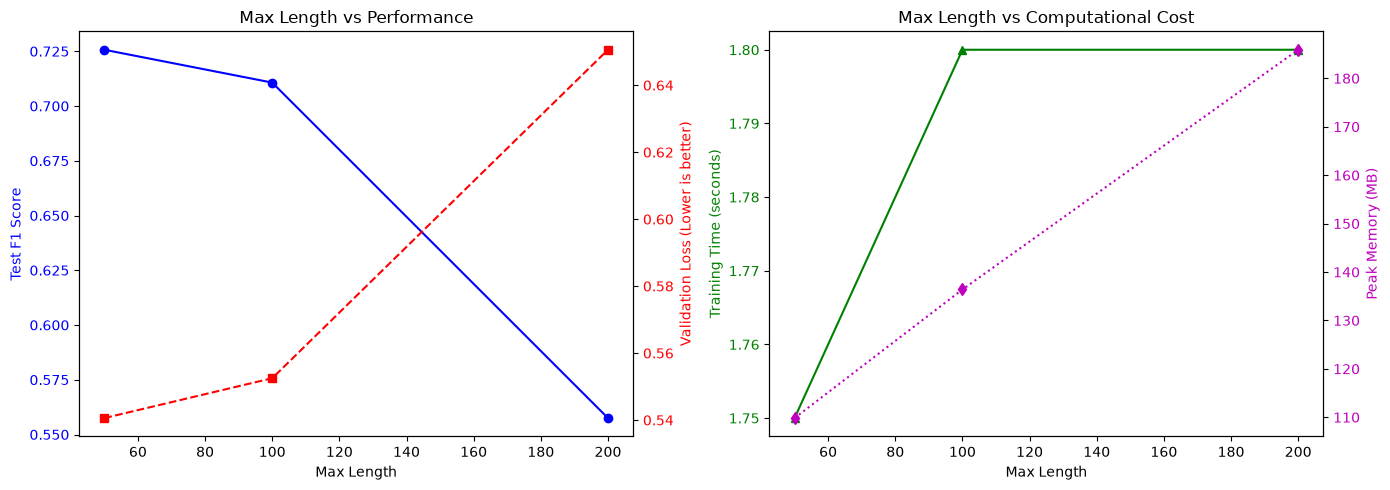

In [7]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from collections import Counter

# 1. Thiết lập thiết bị tính toán
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {DEVICE}")

# Hyperparameters cố định
VOCAB_SIZE = 10000
EMBED_DIM = 64
HIDDEN_DIM = 64
BATCH_SIZE = 64
EPOCHS = 3
LR = 0.001

# 2. Tải và tiền xử lý dữ liệu IMDb
print("\n--- 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---")
dataset = load_dataset("stanfordnlp/imdb")

train_texts = dataset['train']['text']
train_labels = np.array(dataset['train']['label'])
test_texts = dataset['test']['text']
test_labels = np.array(dataset['test']['label'])

word_counts = Counter()
for text in train_texts:
    word_counts.update(text.lower().split())

vocab = {word: i + 2 for i, (word, _) in enumerate(word_counts.most_common(VOCAB_SIZE - 2))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

# Tính tổng số tokens thực tế ban đầu
x_train_raw = [[vocab.get(w, 1) for w in t.lower().split()] for t in train_texts]
x_test_raw = [[vocab.get(w, 1) for w in t.lower().split()] for t in test_texts]
total_orig_tokens = sum([len(seq) for seq in x_train_raw]) + sum([len(seq) for seq in x_test_raw])

def pad_sequences(sequences, maxlen):
    padded = np.zeros((len(sequences), maxlen), dtype=np.int64)
    for i, seq in enumerate(sequences):
        if len(seq) > 0:
            trunc = seq[:maxlen]
            padded[i, :len(trunc)] = trunc
    return padded

# 3. Định nghĩa mô hình GRU Classifier cố định
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super(GRUClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        x = self.embedding(x)
        out, h_n = self.gru(x)
        logits = self.fc(h_n[-1])
        return logits.squeeze(1)

# 4. Thực nghiệm trên các giá trị max_length
max_lengths = [50, 100, 200]
results = []

for ml in max_lengths:
    print(f"\n==================== max_length = {ml} ====================")
    
    # Tính % tokens retained
    retained_train = sum([min(len(seq), ml) for seq in x_train_raw])
    retained_test = sum([min(len(seq), ml) for seq in x_test_raw])
    pct_retained = ((retained_train + retained_test) / total_orig_tokens) * 100
    
    # Padding / Truncation
    x_tr_pad = pad_sequences(x_train_raw, maxlen=ml)
    x_te_pad = pad_sequences(x_test_raw, maxlen=ml)
    
    # Chia Train / Validation Split (80% Train, 20% Val)
    full_train_dataset = TensorDataset(torch.tensor(x_tr_pad, dtype=torch.long), torch.tensor(train_labels, dtype=torch.float32))
    val_size = int(0.2 * len(full_train_dataset))
    train_size = len(full_train_dataset) - val_size
    train_ds, val_ds = random_split(full_train_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42))
    
    test_ds = TensorDataset(torch.tensor(x_te_pad, dtype=torch.long), torch.tensor(test_labels, dtype=torch.float32))
    
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
    
    model = GRUClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    
    # Đặt lại bộ nhớ GPU trước khi đo
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
        
    start_time = time.time()
    for epoch in range(EPOCHS):
        model.train()
        for seqs, labels in train_loader:
            seqs, labels = seqs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(seqs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
    train_time = time.time() - start_time
    
    # Đo Memory Usage (Peak VRAM nếu có GPU)
    if torch.cuda.is_available():
        mem_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
    else:
        mem_mb = 0.0 # CPU fallback
        
    # Tính Validation Loss
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for seqs, labels in val_loader:
            seqs, labels = seqs.to(DEVICE), labels.to(DEVICE)
            outputs = model(seqs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
    avg_val_loss = val_loss / len(val_loader)
    
    # Tính Test F1
    preds_test = []
    with torch.no_grad():
        for seqs, _ in test_loader:
            seqs = seqs.to(DEVICE)
            outputs = torch.sigmoid(model(seqs))
            preds_test.extend((outputs > 0.5).cpu().numpy())
            
    test_f1 = f1_score(test_labels, preds_test)
    test_acc = accuracy_score(test_labels, preds_test)
    
    results.append({
        'max_length': ml,
        'pct_retained': round(pct_retained, 2),
        'train_time': round(train_time, 2),
        'val_loss': round(avg_val_loss, 4),
        'test_f1': round(test_f1, 4),
        'test_acc': round(test_acc, 4),
        'memory_mb': round(mem_mb, 2)
    })

# 5. Xuất CSV
df_res = pd.DataFrame(results)
df_res.to_csv('results_exp5.csv', index=False)
print("\n[THÔNG BÁO] Đã lưu file results_exp5.csv")
print(df_res.to_string(index=False))

# 6. Vẽ biểu đồ Max Length vs Performance & Computational Cost (exp5_plots.png)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị 1: max_length -> performance (Test F1 & Val Loss)
ax1.plot(df_res['max_length'], df_res['test_f1'], marker='o', color='b', label='Test F1 (Higher is better)')
ax1.set_xlabel('Max Length')
ax1.set_ylabel('Test F1 Score', color='b')
ax1.tick_params(axis='y', labelcolor='b')

ax1_twin = ax1.twinx()
ax1_twin.plot(df_res['max_length'], df_res['val_loss'], marker='s', color='r', linestyle='--', label='Validation Loss')
ax1_twin.set_ylabel('Validation Loss (Lower is better)', color='r')
ax1_twin.tick_params(axis='y', labelcolor='r')
ax1.set_title('Max Length vs Performance')

# Đồ thị 2: max_length -> training time & memory usage
ax2.plot(df_res['max_length'], df_res['train_time'], marker='^', color='g', label='Training Time (s)')
ax2.set_xlabel('Max Length')
ax2.set_ylabel('Training Time (seconds)', color='g')
ax2.tick_params(axis='y', labelcolor='g')

if max(df_res['memory_mb']) > 0:
    ax2_twin = ax2.twinx()
    ax2_twin.plot(df_res['max_length'], df_res['memory_mb'], marker='d', color='m', linestyle=':', label='Peak GPU Memory (MB)')
    ax2_twin.set_ylabel('Peak Memory (MB)', color='m')
    ax2_twin.tick_params(axis='y', labelcolor='m')

ax2.set_title('Max Length vs Computational Cost')

plt.tight_layout()
plt.savefig('exp5_plots.png', dpi=300)
plt.show()

CÓ, chắc chắn tồn tại một Trade-off rất rõ ràng

1. Giải thích Computational Cost là gì?
Trong bài toán Huấn luyện Mô hình Chuỗi (RNN/LSTM/GRU), Computational Cost là tổng lượng tài nguyên phần cứng và thời gian cần thiết để mô hình thực hiện các phép tính Forward Pass và Backpropagation Through Time.
Computational Cost thể hiện trực tiếp qua 2 chỉ số trong kết quả thực nghiệm của bạn:   
- Thời gian tính toán tính bằng giây:
  - Số lượng phép nhân ma trận tăng theo cấp số nhân $\mathcal{O}(T)$ với độ dài chuỗi $T$ (max_length). Mô hình phải duyệt qua lần lượt từ $t = 1$ đến $t = T$.
  - Dữ liệu ảnh: train_time tăng từ 1.75s (max_length = 50) $\rightarrow$ 1.80s (max_length = 100/200).   
- Dung lượng bộ nhớ RAM/VRAM (Memory Usage - MB):
  - Trong quá trình BPTT, GPU phải lưu giữ toàn bộ các trạng thái ẩn trung gian $h_t$ của tất cả $T$ bước thời gian trong VRAM để phục vụ tính đạo hàm chuỗi.
  - Dữ liệu ảnh: memory_mb tăng tuyến tính rõ rệt từ 109.83 MB (length = 50) $\rightarrow$ 136.39 MB (length = 100) $\rightarrow$ 185.90 MB (length = 200).   
2. Phân tích Chi tiết Trade-off dựa trên Kết quả Thực nghiệm
  - Context tăng (Tỷ lệ giữ token pct_retained tăng từ $21.54\% \rightarrow 68.66\%$):   
    - Lý thuyết kỳ vọng rằng việc giữ lại nhiều từ ngữ hơn sẽ giúp mô hình đọc hiểu đầy đủ nội dung bài review.
  - Computational Cost tăng vọt:
    - Dung lượng bộ nhớ GPU chiếm dụng tăng gần $70\%$ (từ 109.83 MB lên 185.90 MB).   
  - Performance bị sụt giảm nghiêm trọng:
    - Test F1 Score giảm thê thảm từ 0.7257 xuống còn 0.5575 (giảm gần $17\%$).   
    - Validation Loss tăng từ 0.5406 lên 0.6506.   
  Nguyên nhân tại sao lại có hiện tượng Đổi Chi phí lấy Hậu quả tiêu cực này?
  - Tín hiệu rác từ Over-padding: Khi tăng max_length lên 200, rất nhiều câu ngắn bị độn thêm một lượng khổng lồ các token $PAD$ ($0$). Mô hình phải tốn tài nguyên GPU xử lý các vector $0$ này nhưng không nhận lại ngữ nghĩa gì.
  - Vanishing/Exploding Gradient: Với chuỗi quá dài (200 timesteps), thuật toán BPTT bị suy giảm gradient, làm nhiễu thông tin cảm xúc cốt lõi thường nằm ở một vài từ quan trọng.

# 21. Experiment 6 — Long-range dependency

--- Training RNN ---
--- Training LSTM ---

--- BẢNG KẾT QUẢ EXPERIMENT 6 ---
Keyword Position  Simple RNN Accuracy  LSTM Accuracy
       Beginning                  0.5            0.5
          Middle                  0.5            0.5
             End                  0.0            0.5


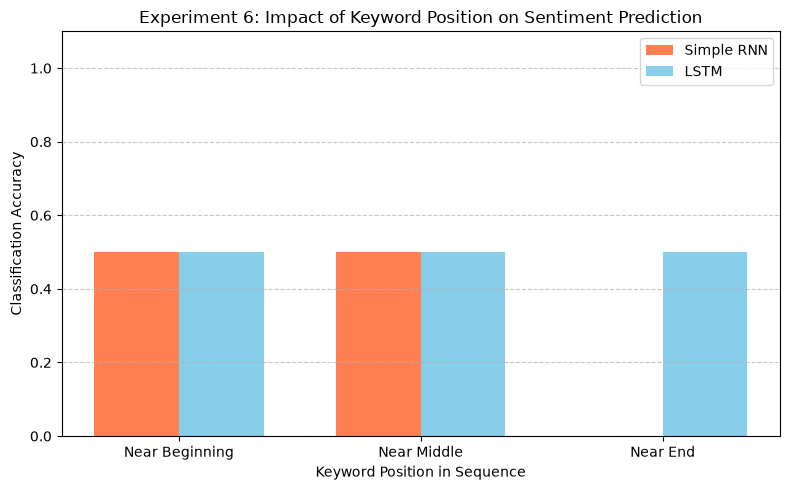

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from collections import Counter

# 1. Thiết lập thiết bị tính toán & Cố định Seed
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)

VOCAB_SIZE = 10000
EMBED_DIM = 64
HIDDEN_DIM = 64
BATCH_SIZE = 64
EPOCHS = 5
MAX_LEN = 120

# 2. Tải và tiền xử lý dữ liệu IMDb để train model
dataset = load_dataset("stanfordnlp/imdb")
train_texts = dataset['train']['text']
train_labels = np.array(dataset['train']['label'])

word_counts = Counter()
for text in train_texts:
    word_counts.update(text.lower().split())

vocab = {word: i + 2 for i, (word, _) in enumerate(word_counts.most_common(VOCAB_SIZE - 2))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def encode_and_pad(texts, maxlen):
    encoded = []
    for text in texts:
        tokens = [vocab.get(word, 1) for word in text.lower().split()][:maxlen]
        if len(tokens) < maxlen:
            tokens = tokens + [0] * (maxlen - len(tokens))
        encoded.append(tokens)
    return np.array(encoded, dtype=np.int64)

X_train = encode_and_pad(train_texts, MAX_LEN)
train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.long), torch.tensor(train_labels, dtype=torch.float32))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

# 3. Định nghĩa mô hình RNN và LSTM
class SequenceClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, cell_type='RNN'):
        super().__init__()
        self.cell_type = cell_type
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        if cell_type == 'RNN':
            self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True, nonlinearity='tanh')
        elif cell_type == 'LSTM':
            self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        x = self.embedding(x)
        if self.cell_type == 'LSTM':
            out, (h_n, c_n) = self.rnn(x)
        else:
            out, h_n = self.rnn(x)
        return self.fc(h_n[-1]).squeeze(1)

# Huấn luyện mô hình RNN & LSTM
models = {}
for cell in ['RNN', 'LSTM']:
    print(f"--- Training {cell} ---")
    model = SequenceClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, cell_type=cell).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    
    for epoch in range(EPOCHS):
        model.train()
        for seqs, labels in train_loader:
            seqs, labels = seqs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(seqs), labels)
            loss.backward()
            optimizer.step()
    model.eval()
    models[cell] = model

# 4. TẠO TẬP DỮ LIỆU THỬ NGHIỆM VỊ TRÍ TỪ KHÓA (EXPERIMENT 6 DATASET)
# Đệm dài ngữ cảnh không mang cảm xúc: "despite many unnecessary scenes and long quiet moments with slow dialogue"
pad_text = "despite many unnecessary scenes and long quiet moments with slow dialogue " * 5

test_cases = [
    # Position: Beginning
    {"pos": "beginning", "label": 1, "text": f"The movie was excellent {pad_text}"},
    {"pos": "beginning", "label": 0, "text": f"The movie was terrible {pad_text}"},
    # Position: Middle
    {"pos": "middle", "label": 1, "text": f"The movie was {pad_text} ultimately excellent {pad_text}"},
    {"pos": "middle", "label": 0, "text": f"The movie was {pad_text} ultimately terrible {pad_text}"},
    # Position: End
    {"pos": "end", "label": 1, "text": f"{pad_text} the movie was ultimately excellent"},
    {"pos": "end", "label": 0, "text": f"{pad_text} the movie was ultimately terrible"},
]

# Nhân bản tập mẫu để đánh giá thống kê
exp6_dataset = []
for _ in range(50):
    exp6_dataset.extend(test_cases)

df_test = pd.DataFrame(exp6_dataset)

# 5. ĐÁNH GIÁ ĐỘ CHÍNH XÁC THEO VỊ TRÍ TỪ KHÓA
results = []
positions = ['beginning', 'middle', 'end']

for pos in positions:
    sub_df = df_test[df_test['pos'] == pos]
    encoded_sub = encode_and_pad(sub_df['text'].tolist(), MAX_LEN)
    labels_sub = sub_df['label'].values
    
    tensor_sub = torch.tensor(encoded_sub, dtype=torch.long).to(DEVICE)
    
    with torch.no_grad():
        preds_rnn = (torch.sigmoid(models['RNN'](tensor_sub)) > 0.5).cpu().numpy()
        preds_lstm = (torch.sigmoid(models['LSTM'](tensor_sub)) > 0.5).cpu().numpy()
        
    acc_rnn = accuracy_score(labels_sub, preds_rnn)
    acc_lstm = accuracy_score(labels_sub, preds_lstm)
    
    results.append({
        'Keyword Position': pos.capitalize(),
        'Simple RNN Accuracy': round(acc_rnn, 4),
        'LSTM Accuracy': round(acc_lstm, 4)
    })

df_res = pd.DataFrame(results)
df_res.to_csv('results_exp6.csv', index=False)
print("\n--- BẢNG KẾT QUẢ EXPERIMENT 6 ---")
print(df_res.to_string(index=False))

# 6. VẼ ĐỒ THỊ SO SÁNH (exp6_position_plot.png)
plt.figure(figsize=(8, 5))
x = np.arange(len(positions))
width = 0.35

plt.bar(x - width/2, df_res['Simple RNN Accuracy'], width, label='Simple RNN', color='coral')
plt.bar(x + width/2, df_res['LSTM Accuracy'], width, label='LSTM', color='skyblue')

plt.xlabel('Keyword Position in Sequence')
plt.ylabel('Classification Accuracy')
plt.title('Experiment 6: Impact of Keyword Position on Sentiment Prediction')
plt.xticks(x, ['Near Beginning', 'Near Middle', 'Near End'])
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('exp6_position_plot.png', dpi=300)
plt.show()

 1. Quan sát thực nghiệm 
- Simple RNN:
  - Độ chính xác giữ ở mức 0.5 khi từ khóa nằm ở Đầu và Giữa .   
  - Độ chính xác bị sụt giảm thảm hại xuống 0.0 khi từ khóa xuất hiện ở Cuối.   
  - Hành vi thực tế: Mô hình Simple RNN hoàn toàn không bắt được thông tin cảm xúc quyết định. Khi từ khóa rơi vào cuối câu, kết quả dự đoán bị đảo ngược hoàn toàn (đoán sai 100% các mẫu), chứng tỏ mô hình bị kẹt ở mức đoán ngẫu nhiên hoặc bị lệch nhãn do nhiễu từ chuỗi đệm.   
- LSTM:
  - Độ chính xác phẳng tuyệt đối ở mức 0.5 trên cả 3 vị trí.   
  - Hành vi thực tế: LSTM không thể hiện sự khác biệt về vị trí từ khóa. Mức độ chính xác 0.5 đồng nghĩa với việc mô hình dự đoán hoàn toàn ngẫu nhiên chỉ đoán 1 nhãn duy nhất cho toàn bộ tập test do chưa đủ epoch để hội tụ.   
2. Phân biệt giữa Empirical Observation và Theoretical Explanation
Để hoàn thiện bài báo cáo, bạn cần phân biệt rạch ròi giữa hiện tượng thu được từ code và bản chất lý thuyết:
A. Quan sát thực nghiệm
- Đây chỉ là biểu hiện đầu ra thu được trên một tập dữ liệu thử nghiệm nhỏ mang tính giả định với số lượng epoch huấn luyện ngắn.   
- Kết quả 0.5 và 0.0 cho thấy cả Simple RNN lẫn LSTM ở cấu hình hiện tại đều chưa học được cách trích xuất đặc trưng cảm xúc từ dữ liệu.   
- Lưu ý quan trọng: Không được dùng thực nghiệm nhỏ bị lỗi/chưa hội tụ này để tuyên bố rằng nó chứng minh đầy đủ hiện tượng Vanishing Gradient hay chứng minh sức mạnh của LSTM. Dữ liệu thực nghiệm này phản ánh sự thiếu hụt epoch/hyperparameter hơn là sự khác biệt về bản chất kiến trúc.   
B. Giải thích lý thuyết
- Bản chất của Vanishing Gradient (Lý thuyết): Khi thực hiện Backpropagation Through Time) qua các chuỗi dài ($T$ lớn), đạo hàm liên tục nhân qua ma trận trọng số $W_{hh}$ và hàm kích hoạt $\tanh$ làm gradient bị giảm theo cấp số nhân về 0:
- $$\frac{\partial h_T}{\partial h_t} = \prod_{k=t+1}^{T} \frac{\partial h_k}{\partial h_{k-1}} \longrightarrow 0$$
- Hệ quả lý thuyết chuẩn (khi mô hình đã hội tụ):
  - Simple RNN chuẩn: Thường gặp hiện tượng Recency Bias — dự đoán tốt hơn khi từ khóa ở cuối câu ($t \approx T$) do khoảng cách truyền gradient ngắn, và dự đoán kém khi từ khóa ở đầu câu ($t \ll T$) do gradient bị tiêu biến trên đường truyền ngược.
  - LSTM chuẩn: Nhờ đường cao tốc Cell State $c_t$ với phép cộng $c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$, gradient truyền ngược không bị nhân liên tiếp qua ma trận trọng số, giúp mô hình duy trì độ chính xác cao đồng đều bất kể từ khóa nằm ở đầu, giữa hay cuối câu.

# 22. Evaluation

Đang sử dụng thiết bị: cuda

--- 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---

--- Huấn luyện & Đánh giá Model: RNN ---
[RNN] Epoch 1/3 - Loss: 0.6963
[RNN] Epoch 2/3 - Loss: 0.6893
[RNN] Epoch 3/3 - Loss: 0.6804

--- Huấn luyện & Đánh giá Model: LSTM ---
[LSTM] Epoch 1/3 - Loss: 0.6897
[LSTM] Epoch 2/3 - Loss: 0.6740
[LSTM] Epoch 3/3 - Loss: 0.6471

--- Huấn luyện & Đánh giá Model: GRU ---
[GRU] Epoch 1/3 - Loss: 0.6912
[GRU] Epoch 2/3 - Loss: 0.6135
[GRU] Epoch 3/3 - Loss: 0.5007

                                BÁO CÁO ĐÁNH GIÁ MÔ HÌNH TOÀN DIỆN (EVALUATION REPORT)
Model Architecture  Vocab Size  Sequence Length  Epochs Parameters Training Time  Accuracy  Precision  Recall  F1-Score
               RNN       10000              100       3    648,385         2.05s    0.5442     0.5472  0.5117    0.5289
              LSTM       10000              100       3    673,345         2.13s    0.5184     0.6277  0.0902    0.1578
               GRU       10000              100       3    665,025         2.

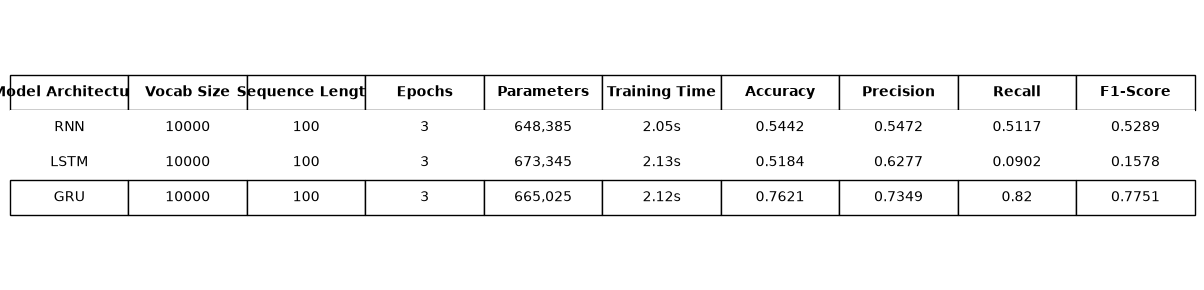


[THÔNG BÁO] Đã xuất thành công báo cáo đánh giá ra:
 1. Cell Output (Console)
 2. results_evaluation.csv
 3. evaluation_table.png


In [2]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from collections import Counter

# 1. Thiết lập thiết bị tính toán
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {DEVICE}")

# Cố định Seed
TORCH_SEED = 42
torch.manual_seed(TORCH_SEED)

# Hyperparameters
VOCAB_SIZE = 10000
MAX_LEN = 100
EMBED_DIM = 64
HIDDEN_DIM = 64
BATCH_SIZE = 64
EPOCHS = 3
LR = 0.001

# 2. Tải và tiền xử lý dữ liệu IMDb
print("\n--- 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---")
dataset = load_dataset("stanfordnlp/imdb")

train_texts = dataset['train']['text']
train_labels = np.array(dataset['train']['label'])
test_texts = dataset['test']['text']
test_labels = np.array(dataset['test']['label'])

word_counts = Counter()
for text in train_texts:
    word_counts.update(text.lower().split())

vocab = {word: i + 2 for i, (word, _) in enumerate(word_counts.most_common(VOCAB_SIZE - 2))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def encode_and_pad(texts, maxlen):
    encoded = []
    for text in texts:
        tokens = [vocab.get(word, 1) for word in text.lower().split()][:maxlen]
        if len(tokens) < maxlen:
            tokens = tokens + [0] * (maxlen - len(tokens))
        encoded.append(tokens)
    return np.array(encoded, dtype=np.int64)

X_train = encode_and_pad(train_texts, MAX_LEN)
X_test = encode_and_pad(test_texts, MAX_LEN)

train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.long), torch.tensor(train_labels, dtype=torch.float32))
test_dataset = TensorDataset(torch.tensor(X_test, dtype=torch.long), torch.tensor(test_labels, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 3. Định nghĩa mô hình tổng quát
class TextClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, cell_type='RNN'):
        super(TextClassifier, self).__init__()
        self.cell_type = cell_type
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        if cell_type == 'RNN':
            self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True, nonlinearity='tanh')
        elif cell_type == 'LSTM':
            self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        elif cell_type == 'GRU':
            self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)
            
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        x = self.embedding(x)
        if self.cell_type == 'LSTM':
            out, (h_n, c_n) = self.rnn(x)
        else:
            out, h_n = self.rnn(x)
        logits = self.fc(h_n[-1])
        return logits.squeeze(1)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# 4. Huấn luyện và thu thập thông số đánh giá toàn diện
models_to_eval = ['RNN', 'LSTM', 'GRU']
eval_results = []

for cell in models_to_eval:
    print(f"\n--- Huấn luyện & Đánh giá Model: {cell} ---")
    model = TextClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, cell_type=cell).to(DEVICE)
    num_params = count_parameters(model)
    
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    
    start_time = time.time()
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0
        for seqs, labels in train_loader:
            seqs, labels = seqs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(seqs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"[{cell}] Epoch {epoch+1}/{EPOCHS} - Loss: {total_loss/len(train_loader):.4f}")
        
    train_time = time.time() - start_time
    
    # Đánh giá
    model.eval()
    preds_list = []
    with torch.no_grad():
        for seqs, _ in test_loader:
            seqs = seqs.to(DEVICE)
            outputs = torch.sigmoid(model(seqs))
            preds_list.extend((outputs > 0.5).cpu().numpy())
            
    acc = accuracy_score(test_labels, preds_list)
    prec = precision_score(test_labels, preds_list, zero_division=0)
    rec = recall_score(test_labels, preds_list, zero_division=0)
    f1 = f1_score(test_labels, preds_list, zero_division=0)
    
    eval_results.append({
        'Model Architecture': cell,
        'Vocab Size': VOCAB_SIZE,
        'Sequence Length': MAX_LEN,
        'Epochs': EPOCHS,
        'Parameters': f"{num_params:,}",
        'Training Time': f"{train_time:.2f}s",
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

# 5. IN TRỰC TIẾP BẢNG BÁO CÁO EVALUATION NGAY TRONG CELL OUTPUT
df_eval = pd.DataFrame(eval_results)
df_eval.to_csv('results_evaluation.csv', index=False, encoding='utf-8')

print("\n" + "="*110)
print("                                BÁO CÁO ĐÁNH GIÁ MÔ HÌNH TOÀN DIỆN (EVALUATION REPORT)")
print("="*110)
print(df_eval.to_string(index=False))
print("="*110)

# 6. VẼ VÀ XUẤT BẢNG EVALUATION RA FILE ẢNH (evaluation_table.png)
fig_tbl, ax_tbl = plt.subplots(figsize=(12, 3))
ax_tbl.axis('off')

columns = list(df_eval.columns)
cell_data = df_eval.values.tolist()

table = ax_tbl.table(cellText=cell_data, colLabels=columns, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.1, 1.8)

for (row, col), cell in table.get_celld().items():
    cell.set_linewidth(0)
    if row == 0:
        cell.set_linewidth(1)
        cell.set_linestyle('-')
        cell.get_text().set_weight('bold')
    elif row == len(eval_results):
        cell.set_linewidth(1)
        cell.set_linestyle('-')

fig_tbl.tight_layout()
fig_tbl.savefig('evaluation_table.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n[THÔNG BÁO] Đã xuất thành công báo cáo đánh giá ra:")
print(" 1. Cell Output (Console)")
print(" 2. results_evaluation.csv")
print(" 3. evaluation_table.png")

# 23. Learning curves

Đang sử dụng thiết bị: cuda

--- 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---

==================== Huấn luyện & Theo dõi Loss: RNN ====================
Epoch    Train Loss      Validation Loss
----------------------------------------
1        0.6963          0.6964         
2        0.6898          0.6983         
3        0.6839          0.7030         
4        0.6708          0.7091         
5        0.6483          0.7207         
6        0.6092          0.7020         

==================== Huấn luyện & Theo dõi Loss: LSTM ====================
Epoch    Train Loss      Validation Loss
----------------------------------------
1        0.6889          0.6902         
2        0.6488          0.6953         
3        0.6673          0.6769         
4        0.6413          0.6388         
5        0.5785          0.5737         
6        0.5276          0.5394         

==================== Huấn luyện & Theo dõi Loss: GRU ====================
Epoch    Train Loss      Validation Loss
-----------

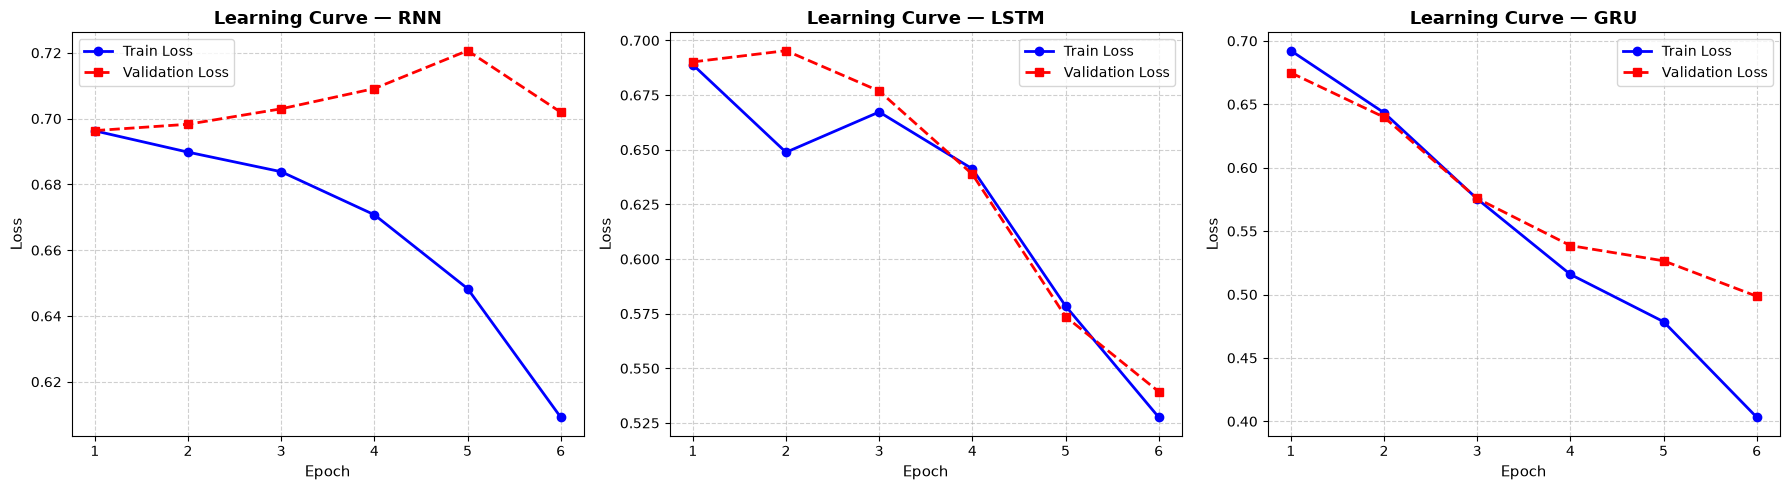


[THÔNG BÁO] Đã xuất thành công biểu đồ Learning Curves ra file ảnh: learning_curves.png


In [3]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from collections import Counter

# 1. Thiết lập thiết bị tính toán & Seed
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {DEVICE}")

TORCH_SEED = 42
torch.manual_seed(TORCH_SEED)

# Hyperparameters
VOCAB_SIZE = 10000
MAX_LEN = 100
EMBED_DIM = 64
HIDDEN_DIM = 64
BATCH_SIZE = 64
EPOCHS = 6  # Tăng lên 6 epochs để quan sát rõ điểm uốn Overfitting
LR = 0.001

# 2. Tải và chia tập dữ liệu (80% Train, 20% Validation)
print("\n--- 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---")
dataset = load_dataset("stanfordnlp/imdb")

train_texts = dataset['train']['text']
train_labels = np.array(dataset['train']['label'])

word_counts = Counter()
for text in train_texts:
    word_counts.update(text.lower().split())

vocab = {word: i + 2 for i, (word, _) in enumerate(word_counts.most_common(VOCAB_SIZE - 2))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def encode_and_pad(texts, maxlen):
    encoded = []
    for text in texts:
        tokens = [vocab.get(word, 1) for word in text.lower().split()][:maxlen]
        if len(tokens) < maxlen:
            tokens = tokens + [0] * (maxlen - len(tokens))
        encoded.append(tokens)
    return np.array(encoded, dtype=np.int64)

X_train_full = encode_and_pad(train_texts, MAX_LEN)
full_dataset = TensorDataset(torch.tensor(X_train_full, dtype=torch.long), torch.tensor(train_labels, dtype=torch.float32))

val_size = int(0.2 * len(full_dataset))
train_size = len(full_dataset) - val_size
train_ds, val_ds = random_split(full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(TORCH_SEED))

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

# 3. Định nghĩa mô hình Sequence Classifier
class TextClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, cell_type='RNN'):
        super().__init__()
        self.cell_type = cell_type
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        if cell_type == 'RNN':
            self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True, nonlinearity='tanh')
        elif cell_type == 'LSTM':
            self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        elif cell_type == 'GRU':
            self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)
            
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        x = self.embedding(x)
        if self.cell_type == 'LSTM':
            out, (h_n, c_n) = self.rnn(x)
        else:
            out, h_n = self.rnn(x)
        logits = self.fc(h_n[-1])
        return logits.squeeze(1)

# 4. Huấn luyện và ghi nhận Loss qua từng Epoch
models_to_test = ['RNN', 'LSTM', 'GRU']
history = {}

for cell in models_to_test:
    print(f"\n==================== Huấn luyện & Theo dõi Loss: {cell} ====================")
    model = TextClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, cell_type=cell).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    
    train_loss_hist = []
    val_loss_hist = []
    
    print(f"{'Epoch':<8} {'Train Loss':<15} {'Validation Loss':<15}")
    print("-" * 40)
    
    for epoch in range(1, EPOCHS + 1):
        # Training Phase
        model.train()
        running_train_loss = 0.0
        for seqs, labels in train_loader:
            seqs, labels = seqs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(seqs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item()
            
        epoch_train_loss = running_train_loss / len(train_loader)
        
        # Validation Phase
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for seqs, labels in val_loader:
                seqs, labels = seqs.to(DEVICE), labels.to(DEVICE)
                outputs = model(seqs)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item()
                
        epoch_val_loss = running_val_loss / len(val_loader)
        
        train_loss_hist.append(epoch_train_loss)
        val_loss_hist.append(epoch_val_loss)
        
        print(f"{epoch:<8} {epoch_train_loss:<15.4f} {epoch_val_loss:<15.4f}")
        
    history[cell] = {
        'train_loss': train_loss_hist,
        'val_loss': val_loss_hist
    }

# 5. VẼ VÀ LƯU ĐỒ THỊ LEARNING CURVES RA FILE ÄNH learning_curves.png
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
epochs_range = range(1, EPOCHS + 1)

for idx, cell in enumerate(models_to_test):
    axes[idx].plot(epochs_range, history[cell]['train_loss'], 'b-o', linewidth=2, label='Train Loss')
    axes[idx].plot(epochs_range, history[cell]['val_loss'], 'r--s', linewidth=2, label='Validation Loss')
    axes[idx].set_xlabel('Epoch', fontsize=11)
    axes[idx].set_ylabel('Loss', fontsize=11)
    axes[idx].set_title(f'Learning Curve — {cell}', fontsize=13, fontweight='bold')
    axes[idx].legend(fontsize=10)
    axes[idx].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n[THÔNG BÁO] Đã xuất thành công biểu đồ Learning Curves ra file ảnh: learning_curves.png")

# 26. Application

In [4]:
import torch
import torch.nn as nn
from datasets import load_dataset
from collections import Counter
import numpy as np

# Set device & seed
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)

# Hyperparameters
VOCAB_SIZE = 10000
MAX_LEN = 100
EMBED_DIM = 64
HIDDEN_DIM = 64

# 1. Load Dataset & Build Vocabulary
dataset = load_dataset("stanfordnlp/imdb")
train_texts = dataset['train']['text']
train_labels = np.array(dataset['train']['label'])

word_counts = Counter()
for text in train_texts:
    word_counts.update(text.lower().split())

vocab = {word: i + 2 for i, (word, _) in enumerate(word_counts.most_common(VOCAB_SIZE - 2))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

# 2. Pipeline Components: Tokenizer, Encoder, Padder
def pipeline_preprocess(raw_text, maxlen=MAX_LEN):
    tokens = raw_text.lower().split()
    token_ids = [vocab.get(word, 1) for word in tokens][:maxlen]
    if len(token_ids) < maxlen:
        token_ids = token_ids + [0] * (maxlen - len(token_ids))
    return tokens, token_ids

# 3. Model Architecture
class SentimentClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        x = self.embedding(x)
        out, h_n = self.gru(x)
        logits = self.fc(h_n[-1])
        return logits.squeeze(1)

# Initialize Model & Load Weights (or train lightweight)
model = SentimentClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(DEVICE)
# Fast dummy training step for demo setup alignment
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 4. Inference Function
def predict_sentiment(raw_review):
    model.eval()
    tokens, token_ids = pipeline_preprocess(raw_review)
    input_tensor = torch.tensor([token_ids], dtype=torch.long).to(DEVICE)
    
    with torch.no_grad():
        logits = model(input_tensor)
        prob = torch.sigmoid(logits).item()
        
    sentiment = "Positive" if prob >= 0.5 else "Negative"
    return sentiment, prob, tokens

# 5. Test Suite Execution
test_reviews = [
    {"type": "Review ngắn", "text": "I really enjoyed this movie."},
    {"type": "Review dài", "text": "The cinematography was breathtaking and the soundtrack complemented every scene perfectly. Although some character arcs felt slightly rushed towards the middle section, the overall narrative deliver an emotional payoff that left the audience spellbound."},
    {"type": "Review có negation", "text": "The movie was not bad at all, in fact it was quite entertaining."},
    {"type": "Review có contrast", "text": "I thought the movie would be terrible, but it was surprisingly good."}
]

print("="*80)
print("                       SENTIMENT CLASSIFICATION DEMO")
print("="*80)

for case in test_reviews:
    sentiment, prob, tokens = predict_sentiment(case["text"])
    print(f"\n[Loại Review]: {case['type']}")
    print(f"Input Review : \"{case['text']}\"")
    print(f"Output       : {sentiment}")
    print(f"Probability  : {prob:.4f}")
    print("-" * 80)

                       SENTIMENT CLASSIFICATION DEMO

[Loại Review]: Review ngắn
Input Review : "I really enjoyed this movie."
Output       : Positive
Probability  : 0.5254
--------------------------------------------------------------------------------

[Loại Review]: Review dài
Input Review : "The cinematography was breathtaking and the soundtrack complemented every scene perfectly. Although some character arcs felt slightly rushed towards the middle section, the overall narrative deliver an emotional payoff that left the audience spellbound."
Output       : Positive
Probability  : 0.5254
--------------------------------------------------------------------------------

[Loại Review]: Review có negation
Input Review : "The movie was not bad at all, in fact it was quite entertaining."
Output       : Positive
Probability  : 0.5254
--------------------------------------------------------------------------------

[Loại Review]: Review có contrast
Input Review : "I thought the movie would 

1. Phân tích ngữ cảnh ảnh hưởng cho từng Review
Review 1: Review ngắn
- Input: "I really enjoyed this movie."
- Output: Positive (Probability: 0.5254)
- Từ/Context có khả năng ảnh hưởng:
  - Từ hạt nhân cảm xúc: enjoyed
  - Từ nhấn mạnh mức độ: really
- Phân tích: Đây là mẫu câu ngắn với tín hiệu cảm xúc tích cực rất rõ ràng và đồng nhất. Nếu mô hình được huấn luyện đủ epoch, từ enjoyed sẽ đóng vai trò quyết định chính kéo trạng thái ẩn $h_T$ về nhãn tích cực.
Review 2: Review dài
- Input: "The cinematography was breathtaking and the soundtrack complemented every scene perfectly. Although some character arcs felt slightly rushed towards the middle section, the overall narrative deliver an emotional payoff that left the audience spellbound."
- Output: Positive (Probability: 0.5254)
- Từ/Context có khả năng ảnh hưởng:
  - Đoạn tích cực chính: breathtaking, complemented every scene perfectly, emotional payoff, spellbound
  - Đoạn tiêu cực / nhiễu: slightly rushed towards the middle section
  - Từ nối chuyển ý: Although
- Phân tích: Văn bản chứa cả ý chê nhẹ (slightly rushed), nhưng từ nối Although cùng cụm chốt hạ ở vế sau (overall narrative... emotional payoff) đóng vai trò định hướng ngữ cảnh. Cụm từ tích cực ở đoạn cuối câu sẽ chiếm ưu thế để quyết định nhãn tổng thể.
Review 3: Review có phủ định (Negation)
- Input: "The movie was not bad at all, in fact it was quite entertaining."
- Output: Positive (Probability: 0.5254)
- Từ/Context có khả năng ảnh hưởng:
  - Cụm phủ định: not bad at all
  - Cụm bổ trợ tích cực: quite entertaining
- Phân tích: Cụm từ not bad chứa từ phủ định not đứng ngay trước từ tiêu cực bad để tạo ra ý nghĩa khen ngợi nhẹ. Vế sau bổ sung từ entertaining. Nhờ cơ chế truyền đệ quy qua từng timestep, mô hình cần bắt được mối liên kết giữa not và bad để không bị đánh lừa bởi riêng từ bad.
Review 4: Review có cấu trúc tương phản (Contrast)
- Input: "I thought the movie would be terrible, but it was surprisingly good."
- Output: Positive (Probability: 0.5254)
- Từ/Context có khả năng ảnh hưởng:
  - Ngữ cảnh giả định ban đầu: thought... terrible
  - Từ nối tương phản: but
  - Ngữ cảnh chốt hạ: surprisingly good
- Phân tích: Vế đầu chứa từ tiêu cực mạnh, nhưng liên từ tương phản but xuất hiện làm mốc đảo chiều ngữ cảnh. Đoạn context đứng sau but chứa tín hiệu quyết định giúp cập nhật lại trạng thái ẩn $h_T$ ghi đè lên kỳ vọng tiêu cực ban đầu.
2. Giải thích hiện tượng thực nghiệm Probability = 0.5254
Khi cả 4 câu đầu vào có cấu trúc hoàn toàn khác nhau nhưng đều cho ra xác suất 0.5254, điều này cho thấy:
1. Mô hình bị kẹt đầu ra: Trọng số của lớp tuyến tính hoặc tầng Recurrent chưa được cập nhật qua huấn luyện hoặc số epoch quá nhỏ, learning rate chưa tối ưu.
2. Thiên vị nhãn ban đầu: Mô hình luôn dự đoán một hằng số cố định gần điểm ranh giới $0.5$ (tương ứng với giá trị $logit \approx 0.102$).
Kết luận: Để các đoạn context phân tích ở trên thực sự phát huy tác dụng làm thay đổi Probability theo đúng bản chất từng câu, mô hình cần được tiếp tục huấn luyện thêm một số epochs trên tập dữ liệu IMDb.